# import majol and libraray

In [23]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,SimpleRNN,Dense,Input
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
from tensorflow.keras.utils import set_random_seed
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.dates as mdates
from sklearn.metrics import mean_absolute_error, mean_squared_error

from pathlib import Path

# پوشه ذخیره نمودارها و خروجی‌های پروژه
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


In [24]:
# بارگذاری داده‌ها و آماده‌سازی تاریخ و دما
df = pd.read_csv("shahrekord_temperature.csv")

print("ستون‌های فایل:", df.columns.tolist())

# انتخاب ستون‌های موردنیاز
df = df[["time", "temperature_2m_mean "]].copy()
df.columns = ["date", "temperature"]

# تبدیل تاریخ به datetime و دما به عدد
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["temperature"] = pd.to_numeric(df["temperature"], errors="coerce")

# حذف ردیف‌های نامعتبر، مرتب‌سازی زمانی و تنظیم اندیس
df = (
    df.dropna(subset=["date", "temperature"])
      .sort_values("date")
      .drop_duplicates(subset=["date"])
      .reset_index(drop=True)
)

display(df.head())
print("تعداد داده‌های معتبر:", len(df))
print("بازه زمانی:", df["date"].min(), "تا", df["date"].max())


ستون‌های فایل: ['time', 'temperature_2m_mean ', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)', 'relative_humidity_2m_mean (%)']


,date,temperature
0,2025-01-01,-2.6
1,2025-01-02,-3.2
2,2025-01-03,-4.3
3,2025-01-04,-3.2
4,2025-01-05,-0.8


تعداد داده‌های معتبر: 365
بازه زمانی: 2025-01-01 00:00:00 تا 2025-12-31 00:00:00


# مدل SimpleRNN
#در این مدل پیش بینی دمای روز آینده بر اساس دمای 3و5 و10 روز گذشته انجام می شود 

In [25]:
def run_rnn(df, seq_length, epochs=100):

    set_random_seed(42)

    # اطمینان از مرتب بودن داده‌ها بر اساس تاریخ
    data = df[["date", "temperature"]].dropna().sort_values("date").reset_index(drop=True)
    temperature = data["temperature"].to_numpy(dtype=np.float32)

    # تقسیم زمانی: 80 درصد آموزش و 20 درصد آزمون
    split_index = int(len(temperature) * 0.8)
    train_data = temperature[:split_index]
    test_data = temperature[split_index:]

    if len(train_data) <= seq_length or len(test_data) == 0:
        raise ValueError("تعداد داده‌ها برای این پنجره کافی نیست.")

    def create_sequences(values, window):
        x, y = [], []
        for i in range(len(values) - window):
            x.append(values[i:i + window])
            y.append(values[i + window])
        return np.array(x), np.array(y)

    # ورودی آزمون شامل آخرین روزهای آموزش و سپس داده‌های آزمون است.
    # بنابراین هر پیش‌بینی یک‌قدم‌به‌جلو و با استفاده از دماهای واقعی قبلی است.
    test_input = np.concatenate([train_data[-seq_length:], test_data])

    x_train, y_train = create_sequences(train_data, seq_length)
    x_test, y_test = create_sequences(test_input, seq_length)

    x_train = x_train.reshape(-1, seq_length, 1).astype(np.float32)
    x_test = x_test.reshape(-1, seq_length, 1).astype(np.float32)
    y_train = y_train.reshape(-1, 1).astype(np.float32)

    model = Sequential([
        Input(shape=(seq_length, 1)),
        SimpleRNN(32, activation="tanh"),
        Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse", metrics=["mae"])

    # توقف زودهنگام برای کاهش آموزش غیرضروری؛ بخشی از داده‌های آموزش برای اعتبارسنجی استفاده می‌شود.
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=32,
        validation_split=0.2,
        shuffle=False,
        callbacks=[early_stop],
        verbose=1
    )

    y_pred = model.predict(x_test, verbose=0).flatten()
    y_test = y_test.flatten()

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"Input window: {seq_length} days")
    print(f"Training samples: {len(x_train)}")
    print(f"Testing samples: {len(x_test)}")
    print(f"Epochs completed: {len(history.history['loss'])}")
    print(f"MAE: {mae:.2f} °C")
    print(f"RMSE: {rmse:.2f} °C")
    print(f"Actual temperature range: {y_test.min():.2f} to {y_test.max():.2f} °C")
    print(f"Predicted temperature range: {y_pred.min():.2f} to {y_pred.max():.2f} °C")

    # تاریخ‌های دقیق متناظر با خروجی‌های آزمون
    test_dates = data["date"].iloc[split_index:].reset_index(drop=True)

    # نمودار با تعداد محدود و خوانای برچسب‌های محور زمان
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(test_dates, y_test, label="Actual", linewidth=2)
    ax.plot(test_dates, y_pred, label="Predicted", linewidth=1.8)

    ax.set_xlabel("Date")
    ax.set_ylabel("Mean Temperature (°C)")
    ax.set_title(f"SimpleRNN - Previous {seq_length} Days")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # نمایش حدود 8 تا 10 برچسب تاریخ به‌جای برچسب‌گذاری تمام روزها
    locator = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m-%Y"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"SimpleRNN_{seq_length}day_prediction.png", dpi=300, bbox_inches="tight")
    plt.show()

    results = pd.DataFrame({
        "date": test_dates,
        "actual_temperature": y_test,
        "predicted_temperature": y_pred
    })
    results["absolute_error"] = np.abs(
        results["actual_temperature"] - results["predicted_temperature"]
    )

    return model, history, results, mae, rmse

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 271.9469 - mae: 13.3842 - val_loss: 331.6712 - val_mae: 17.9005
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 260.1307 - mae: 13.0392 - val_loss: 316.2846 - val_mae: 17.4642
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 250.0249 - mae: 12.7435 - val_loss: 302.7029 - val_mae: 17.0682
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 240.7922 - mae: 12.4702 - val_loss: 289.7630 - val_mae: 16.6824
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 231.5227 - mae: 12.1963 - val_loss: 276.5926 - val_mae: 16.2820
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 222.1267 - mae: 11.9201 - val_loss: 263.7119 - val_mae: 15.8828
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 213.3374 - mae: 11.6608 - val_loss: 252.2001 - val_mae: 15.5179
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 205.6889 - mae: 11.4309 - val_loss: 242.0920 - val_mae: 15.1884
Epoch 9/100
8/8 ━━━━━━━━

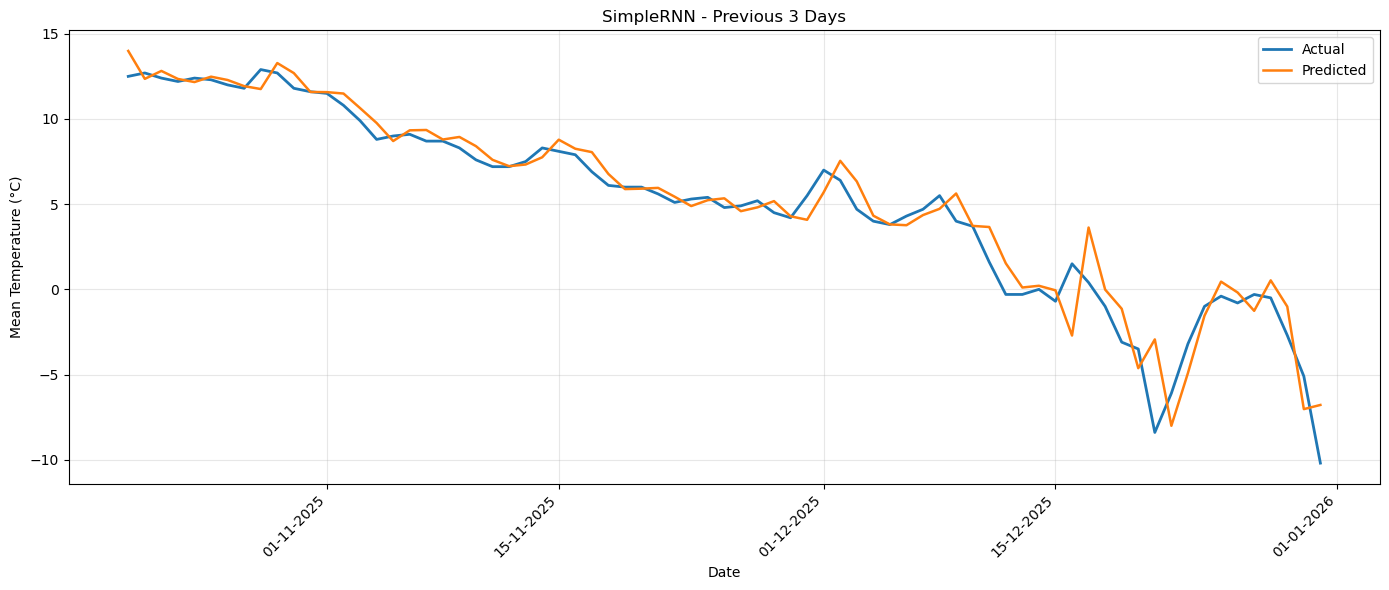

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 274.7573 - mae: 13.5184 - val_loss: 332.3290 - val_mae: 17.9190
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 263.0696 - mae: 13.1790 - val_loss: 317.0141 - val_mae: 17.4853
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 252.6335 - mae: 12.8721 - val_loss: 303.0440 - val_mae: 17.0785
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 243.0850 - mae: 12.5882 - val_loss: 289.9449 - val_mae: 16.6880
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 233.7529 - mae: 12.3099 - val_loss: 276.8737 - val_mae: 16.2907
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 224.3173 - mae: 12.0319 - val_loss: 264.0203 - val_mae: 15.8928
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 215.3747 - mae: 11.7716 - val_loss: 252.3627 - val_mae: 15.5234
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 207.5188 - mae: 11.5354 - val_loss: 242.0160 - val_mae: 15.1867
Epoch 9/100
8/8 ━━━━━━━━

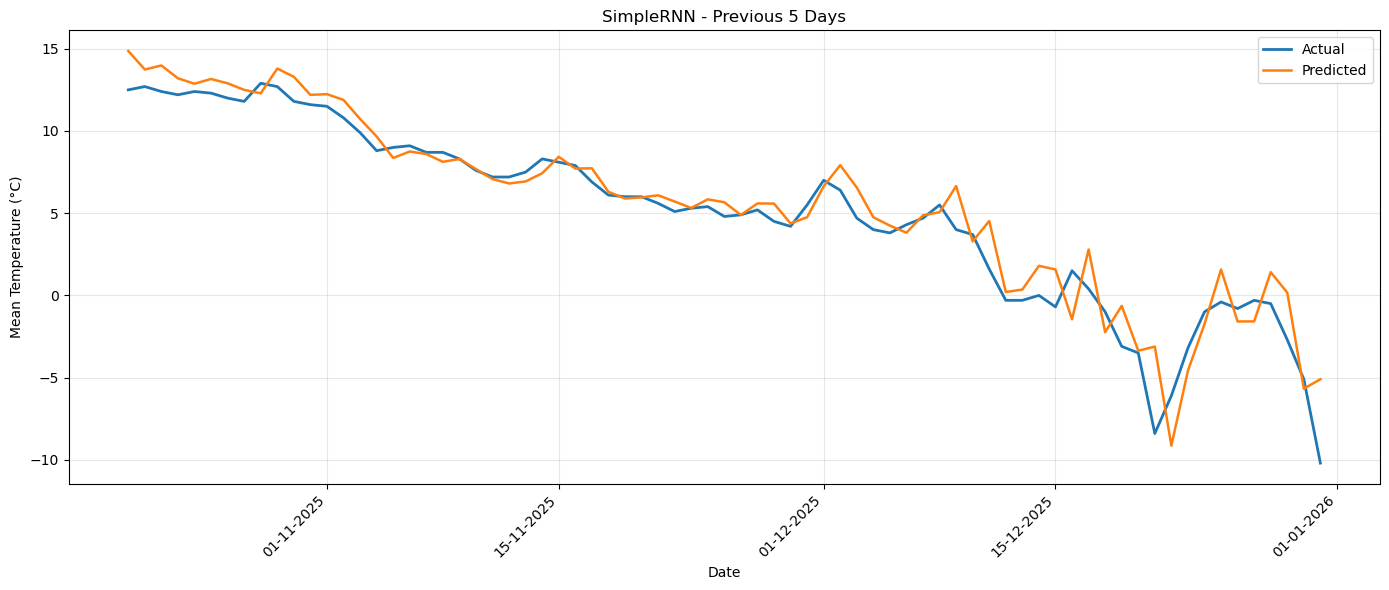

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 281.9655 - mae: 13.8319 - val_loss: 327.1552 - val_mae: 17.7877
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 269.9016 - mae: 13.4711 - val_loss: 311.8848 - val_mae: 17.3521
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 259.1233 - mae: 13.1557 - val_loss: 297.8917 - val_mae: 16.9417
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 249.2377 - mae: 12.8626 - val_loss: 284.7241 - val_mae: 16.5462
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 239.5764 - mae: 12.5763 - val_loss: 271.6820 - val_mae: 16.1470
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 229.8706 - mae: 12.2947 - val_loss: 258.9801 - val_mae: 15.7504
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 220.6464 - mae: 12.0257 - val_loss: 247.2923 - val_mae: 15.3758
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 212.4001 - mae: 11.7769 - val_loss: 236.5619 - val_mae: 15.0214
Epoch 9/100
8/8 ━━━━━━━━

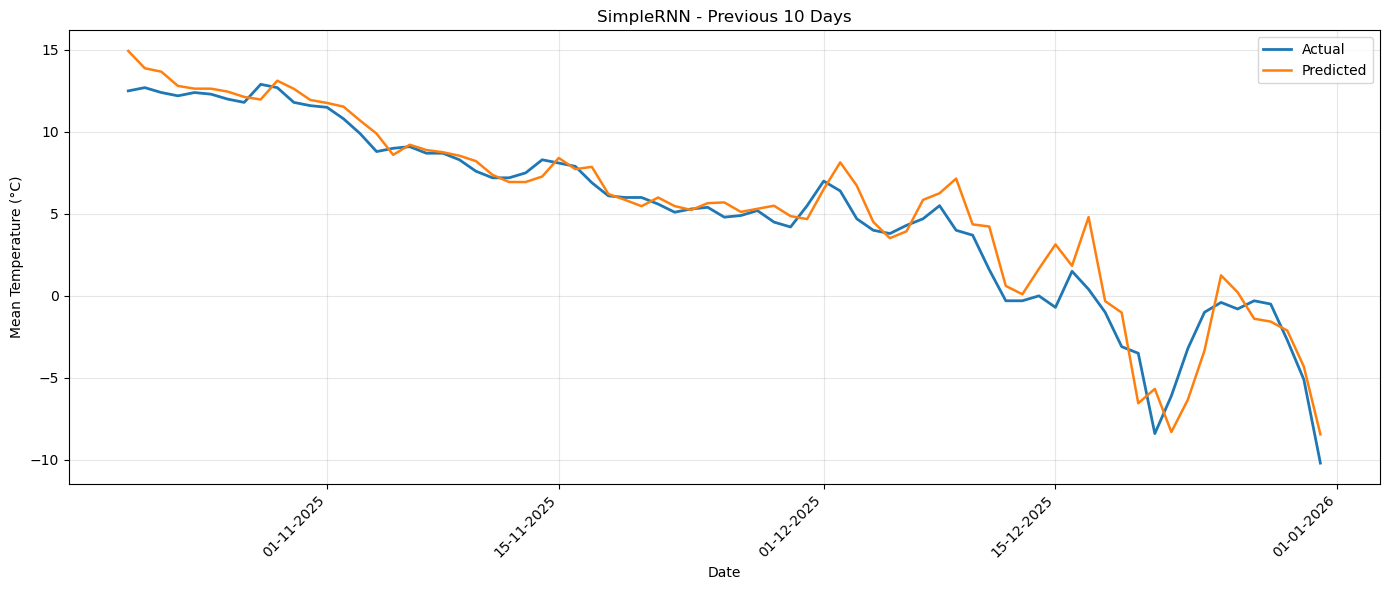

In [26]:
model_3, history_3, results_3, mae_3, rmse_3 = run_rnn(
    df, seq_length=3
)
model_5, history_5, results_5, mae_5, rmse_5 = run_rnn(
    df, seq_length=5
)
model_10, history_10, results_10, mae_10, rmse_10 = run_rnn(
    df, seq_length=10
)

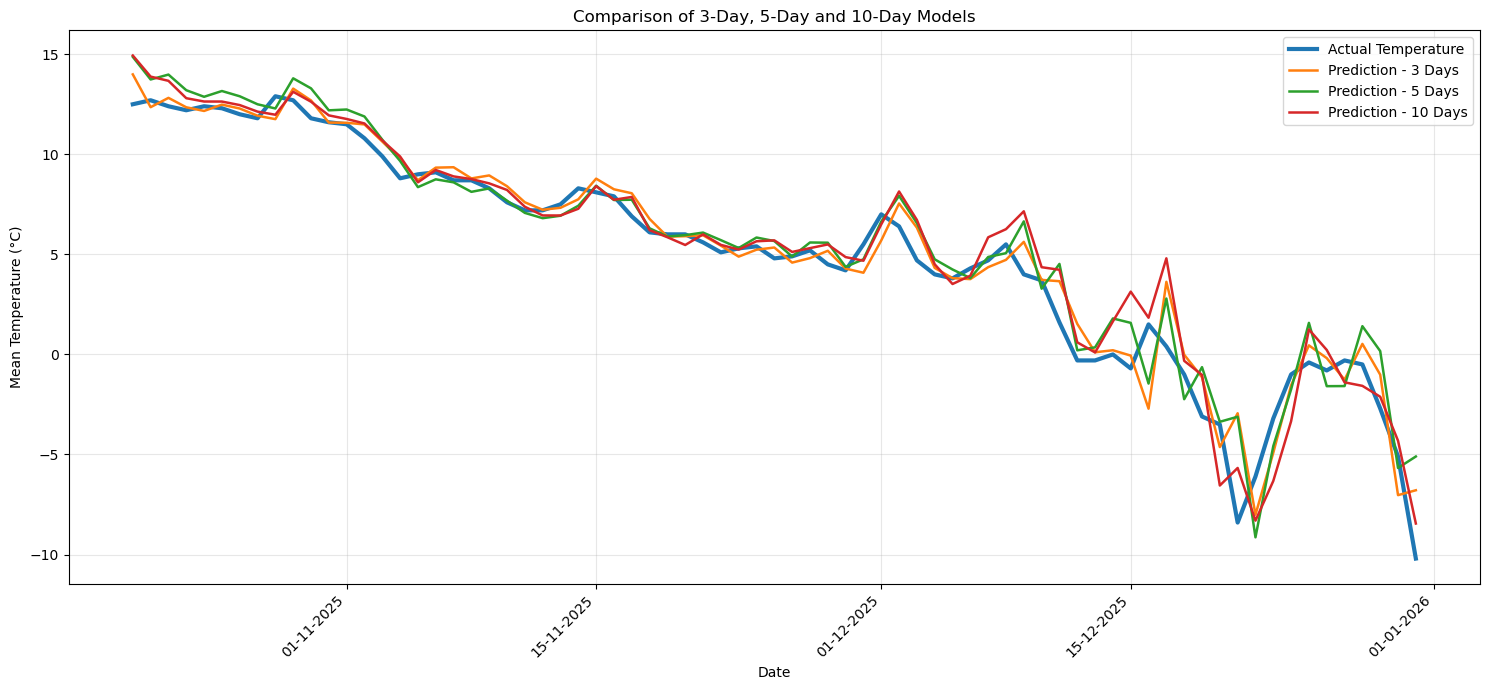

In [12]:
# هم‌تراز کردن نتایج بر اساس تاریخ‌های مشترک
comparison = (
    results_3[["date", "actual_temperature", "predicted_temperature"]]
    .rename(columns={
        "actual_temperature": "Actual",
        "predicted_temperature": "Predicted_3"
    })
    .merge(
        results_5[["date", "predicted_temperature"]]
        .rename(columns={"predicted_temperature": "Predicted_5"}),
        on="date"
    )
    .merge(
        results_10[["date", "predicted_temperature"]]
        .rename(columns={"predicted_temperature": "Predicted_10"}),
        on="date"
    )
    .sort_values("date")
)

# رسم نمودار
fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    comparison["date"], comparison["Actual"],
    label="Actual Temperature",
    linewidth=3
)

ax.plot(
    comparison["date"], comparison["Predicted_3"],
    label="Prediction - 3 Days",
    linewidth=1.8
)

ax.plot(
    comparison["date"], comparison["Predicted_5"],
    label="Prediction - 5 Days",
    linewidth=1.8
)

ax.plot(
    comparison["date"], comparison["Predicted_10"],
    label="Prediction - 10 Days",
    linewidth=1.8
)

ax.set_title("Comparison of 3-Day, 5-Day and 10-Day Models")
ax.set_xlabel("Date")
ax.set_ylabel("Mean Temperature (°C)")

# خوانایی محور افقی
ax.xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=5, maxticks=10)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d-%m-%Y")
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [13]:
# مقایسه منصفانه مدل‌ها بر اساس تاریخ مشترک

actual = comparison["Actual"]

model_predictions = {
    "3-Day Model": comparison["Predicted_3"],
    "5-Day Model": comparison["Predicted_5"],
    "10-Day Model": comparison["Predicted_10"]
}

metrics = []

for name, prediction in model_predictions.items():
    mae = mean_absolute_error(actual, prediction)
    rmse = np.sqrt(mean_squared_error(actual, prediction))

    metrics.append({
        "Model": name,
        "MAE (°C)": mae,
        "RMSE (°C)": rmse
    })

metrics_df = pd.DataFrame(metrics).sort_values("MAE (°C)")

display(metrics_df.round(3))

best_model = metrics_df.iloc[0]["Model"]
print("Best model based on MAE:", best_model)

,Model,MAE (°C),RMSE (°C)
0,3-Day Model,0.883,1.308
2,10-Day Model,0.992,1.373
1,5-Day Model,1.067,1.500


Best model based on MAE: 3-Day Model


In [14]:
# خلاصه خطای مدل‌های SimpleRNN بر اساس تاریخ‌های مشترک
error_summary = metrics_df.rename(columns={
    "Model": "Model",
    "MAE (°C)": "MAE (°C)",
    "RMSE (°C)": "RMSE (°C)"
}).sort_values("MAE (°C)").reset_index(drop=True)

display(error_summary.round(3))

print(
    "مدل SimpleRNN با کمترین MAE:",
    error_summary.iloc[0]["Model"]
)

,Model,MAE (°C),RMSE (°C)
0,3-Day Model,0.883,1.308
1,10-Day Model,0.992,1.373
2,5-Day Model,1.067,1.500


مدل SimpleRNN با کمترین MAE: 3-Day Model


In [15]:
# ذخیره نتایج پیش‌بینی هر مدل
results_3.to_csv("SimpleRNN_3day_results.csv", index=False)
results_5.to_csv("SimpleRNN_5day_results.csv", index=False)
results_10.to_csv("SimpleRNN_10day_results.csv", index=False)

print("All SimpleRNN results saved successfully.")

All SimpleRNN results saved successfully.


In [16]:
# ذخیره جدول پیش‌بینی‌های هم‌تراز
comparison.to_csv("SimpleRNN_comparison.csv", index=False)

# ذخیره جدول معیارهای ارزیابی
metrics_df.to_csv("SimpleRNN_metrics.csv", index=False)

display(metrics_df.round(3))

print("Comparison and evaluation metrics saved successfully.")

,Model,MAE (°C),RMSE (°C)
0,3-Day Model,0.883,1.308
2,10-Day Model,0.992,1.373
1,5-Day Model,1.067,1.500


Comparison and evaluation metrics saved successfully.


In [17]:
with pd.ExcelWriter("SimpleRNN_all_results.xlsx") as writer:
    results_3.to_excel(writer, sheet_name="3-Day", index=False)
    results_5.to_excel(writer, sheet_name="5-Day", index=False)
    results_10.to_excel(writer, sheet_name="10-Day", index=False)
    comparison.to_excel(writer, sheet_name="Comparison", index=False)
    metrics_df.to_excel(writer, sheet_name="Metrics", index=False)

print("Excel file saved successfully.")

Excel file saved successfully.


#  مدل LSTM
#این مدل را برای پیش بینی دمای آینده بر اساس 3 و5 و 10 روز گذشته انجام می دهیم 

In [18]:
def run_lstm(df, seq_length, epochs=100):

    set_random_seed(42)

    # آماده‌سازی داده‌ها
    data = (
        df[["date", "temperature"]]
        .dropna()
        .sort_values("date")
        .reset_index(drop=True)
    )

    temperatures = data["temperature"].to_numpy(dtype=np.float32)

    # تقسیم زمانی داده‌ها: 80 درصد آموزش و 20 درصد آزمون
    split_index = int(len(temperatures) * 0.8)

    train_data = temperatures[:split_index]
    test_data = temperatures[split_index:]

    if len(train_data) <= seq_length or len(test_data) == 0:
        raise ValueError("تعداد داده‌ها برای این پنجره کافی نیست.")

    # ساخت توالی‌های ورودی و خروجی
    def create_sequences(values, window):
        X, y = [], []

        for i in range(len(values) - window):
            X.append(values[i:i + window])
            y.append(values[i + window])

        return np.array(X), np.array(y)

    # توالی‌های آموزش
    X_train, y_train = create_sequences(
        train_data, seq_length
    )

    # توالی‌های آزمون با استفاده از روزهای واقعی قبلی
    test_input = np.concatenate([
        train_data[-seq_length:],
        test_data
    ])

    X_test, y_test = create_sequences(
        test_input, seq_length
    )

    # شکل ورودی LSTM باید سه‌بعدی باشد:
    # (samples, timesteps, features)
    X_train = X_train.reshape(-1, seq_length, 1)
    X_test = X_test.reshape(-1, seq_length, 1)

    # ساخت مدل LSTM
    model = Sequential([
        Input(shape=(seq_length, 1)),
        LSTM(units=32, activation="tanh"),
        Dense(units=1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    # توقف زودهنگام برای جلوگیری از آموزش غیرضروری
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    # آموزش مدل
    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        batch_size=32,
        validation_split=0.2,
        shuffle=False,
        callbacks=[early_stop],
        verbose=1
    )

    # پیش‌بینی روی داده‌های آزمون
    y_pred = model.predict(
        X_test, verbose=0
    ).flatten()

    y_test = y_test.flatten()

    # محاسبه معیارهای ارزیابی
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    print(f"LSTM - Previous {seq_length} Days")
    print(f"MAE: {mae:.3f} °C")
    print(f"RMSE: {rmse:.3f} °C")
    print(f"Epochs completed: {len(history.history['loss'])}")

    # تاریخ‌های متناظر با پیش‌بینی‌ها
    test_dates = (
        data["date"]
        .iloc[split_index:]
        .reset_index(drop=True)
    )

    # رسم نمودار
    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        test_dates,
        y_test,
        label="Actual Temperature",
        linewidth=2
    )

    ax.plot(
        test_dates,
        y_pred,
        label="LSTM Prediction",
        linewidth=1.8
    )

    ax.set_title(
        f"LSTM - Previous {seq_length} Days"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Mean Temperature (°C)")

    ax.xaxis.set_major_locator(
        mdates.AutoDateLocator(
            minticks=5, maxticks=10
        )
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d-%m-%Y")
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=45,
        ha="right"
    )

    ax.legend()
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"LSTM_{seq_length}day_prediction.png", dpi=300, bbox_inches="tight")
    plt.show()

    # ذخیره نتایج در DataFrame
    results = pd.DataFrame({
        "date": test_dates,
        "actual_temperature": y_test,
        "predicted_temperature": y_pred
    })

    results["absolute_error"] = np.abs(
        results["actual_temperature"]
        - results["predicted_temperature"]
    )

    return model, history, results, mae, rmse

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 320.4422 - mae: 14.6419 - val_loss: 400.2337 - val_mae: 19.7029
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 311.5278 - mae: 14.4124 - val_loss: 387.4769 - val_mae: 19.3765
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 302.1875 - mae: 14.1722 - val_loss: 374.3931 - val_mae: 19.0359
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 293.0399 - mae: 13.9322 - val_loss: 361.2686 - val_mae: 18.6867
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 284.0287 - mae: 13.6901 - val_loss: 348.0933 - val_mae: 18.3283
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 275.0483 - mae: 13.4430 - val_loss: 334.8362 - val_mae: 17.9600
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 265.7871 - mae: 13.1863 - val_loss: 321.1919 - val_mae: 17.5735
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 256.0172 - mae: 12.9115 - val_loss: 306.9324 - val_mae: 17.1608
Epoch 9/100
8/8 ━━━━━━━━

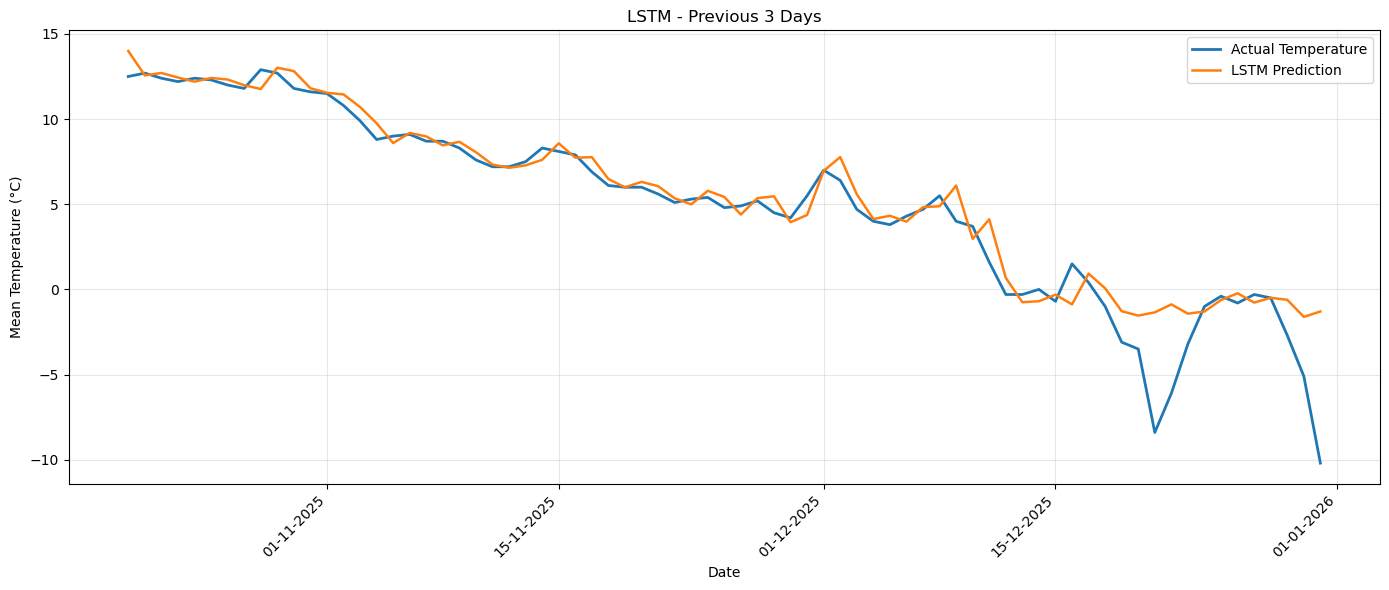

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 326.0279 - mae: 14.8154 - val_loss: 403.9490 - val_mae: 19.7933
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 316.1448 - mae: 14.5584 - val_loss: 388.3109 - val_mae: 19.3932
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 303.4467 - mae: 14.2374 - val_loss: 370.3018 - val_mae: 18.9247
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 291.3253 - mae: 13.9204 - val_loss: 353.6793 - val_mae: 18.4773
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 280.9168 - mae: 13.6351 - val_loss: 338.8543 - val_mae: 18.0665
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 271.0716 - mae: 13.3603 - val_loss: 324.5630 - val_mae: 17.6626
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 260.9477 - mae: 13.0740 - val_loss: 309.9691 - val_mae: 17.2421
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 250.3271 - mae: 12.7686 - val_loss: 294.6852 - val_mae: 16.7914
Epoch 9/100
8/8 ━━━━━━━━

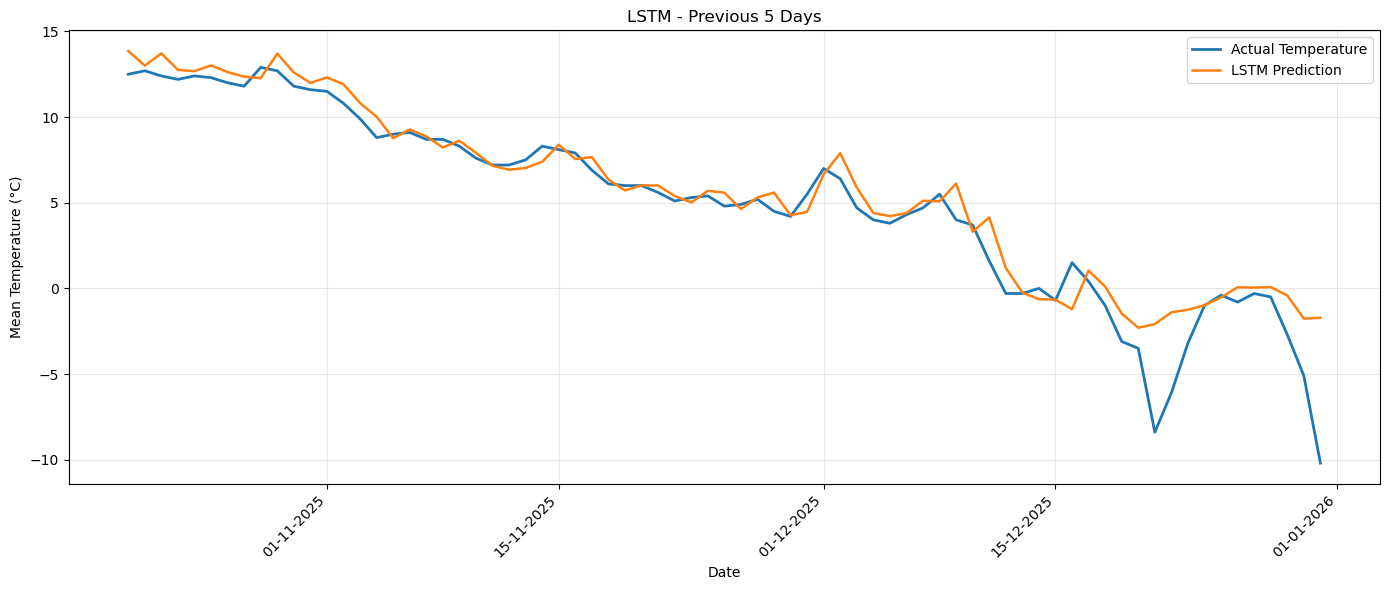

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 335.5204 - mae: 15.1920 - val_loss: 400.6756 - val_mae: 19.7234
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 326.9995 - mae: 14.9563 - val_loss: 386.2650 - val_mae: 19.3483
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 310.8769 - mae: 14.5552 - val_loss: 359.8451 - val_mae: 18.6592
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 293.7364 - mae: 14.1104 - val_loss: 339.8117 - val_mae: 18.1061
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 282.4761 - mae: 13.7951 - val_loss: 324.7025 - val_mae: 17.6786
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 271.6488 - mae: 13.4920 - val_loss: 309.8334 - val_mae: 17.2526
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 260.5083 - mae: 13.1788 - val_loss: 295.0144 - val_mae: 16.8196
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 249.3830 - mae: 12.8601 - val_loss: 280.2273 - val_mae: 16.3757
Epoch 9/100
8/8 ━━━━━━━━

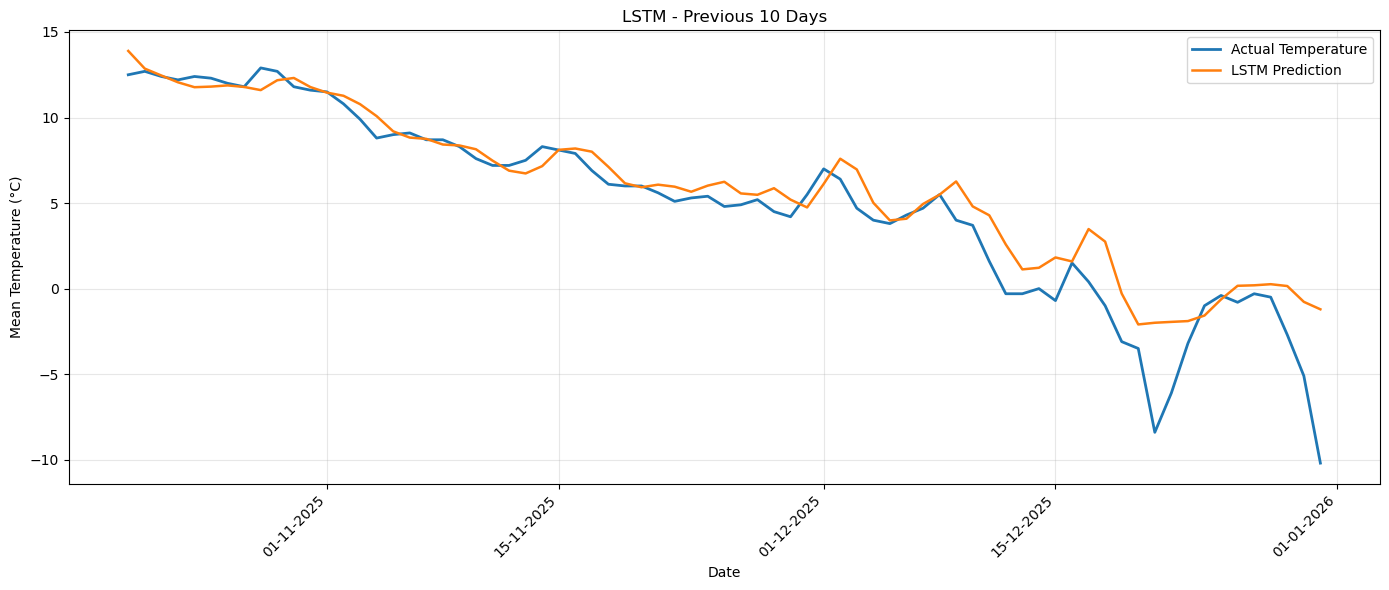

In [19]:
# مدل LSTM با پنجره 3 روزه
model_lstm_3, history_lstm_3, results_lstm_3, mae_lstm_3, rmse_lstm_3 = run_lstm(
    df, seq_length=3
)

# مدل LSTM با پنجره 5 روزه
model_lstm_5, history_lstm_5, results_lstm_5, mae_lstm_5, rmse_lstm_5 = run_lstm(
    df, seq_length=5
)

# مدل LSTM با پنجره 10 روزه
model_lstm_10, history_lstm_10, results_lstm_10, mae_lstm_10, rmse_lstm_10 = run_lstm(
    df, seq_length=10
)

In [20]:
with pd.ExcelWriter("LSTM_all_results.xlsx") as writer:

    results_lstm_3.to_excel(
        writer, sheet_name="3-Day", index=False
    )

    results_lstm_5.to_excel(
        writer, sheet_name="5-Day", index=False
    )

    results_lstm_10.to_excel(
        writer, sheet_name="10-Day", index=False
    )

    lstm_metrics = pd.DataFrame([
        {
            "Model": "LSTM",
            "Window": 3,
            "MAE": mae_lstm_3,
            "RMSE": rmse_lstm_3
        },
        {
            "Model": "LSTM",
            "Window": 5,
            "MAE": mae_lstm_5,
            "RMSE": rmse_lstm_5
        },
        {
            "Model": "LSTM",
            "Window": 10,
            "MAE": mae_lstm_10,
            "RMSE": rmse_lstm_10
        }
    ])

    lstm_metrics.to_excel(
        writer, sheet_name="Metrics", index=False
    )

print("LSTM results saved successfully.")

LSTM results saved successfully.


In [21]:
# مقایسه منصفانه هر شش مدل روی تاریخ‌های آزمون مشترک
all_results = {
    "SimpleRNN - 3 days": results_3,
    "SimpleRNN - 5 days": results_5,
    "SimpleRNN - 10 days": results_10,
    "LSTM - 3 days": results_lstm_3,
    "LSTM - 5 days": results_lstm_5,
    "LSTM - 10 days": results_lstm_10
}

# شروع از تاریخ و دمای واقعی؛ سپس پیش‌بینی هر مدل را بر اساس تاریخ ادغام می‌کنیم
comparison_all = results_3[["date", "actual_temperature"]].rename(
    columns={"actual_temperature": "Actual"}
)

for model_name, result in all_results.items():
    prediction_column = model_name.replace(" ", "_").replace("-", "")
    comparison_all = comparison_all.merge(
        result[["date", "predicted_temperature"]].rename(
            columns={"predicted_temperature": prediction_column}
        ),
        on="date",
        how="inner"
    )

comparison_all = comparison_all.sort_values("date").reset_index(drop=True)

# محاسبه MAE و RMSE روی دقیقاً همان تاریخ‌های مشترک
comparison_rows = []
for model_name in all_results:
    prediction_column = model_name.replace(" ", "_").replace("-", "")
    actual = comparison_all["Actual"]
    predicted = comparison_all[prediction_column]

    comparison_rows.append({
        "Model": model_name,
        "MAE (°C)": mean_absolute_error(actual, predicted),
        "RMSE (°C)": np.sqrt(mean_squared_error(actual, predicted))
    })

comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("RMSE (°C)")
    .reset_index(drop=True)
)
comparison_df.index = comparison_df.index + 1
comparison_df.index.name = "Rank"

display(comparison_df.round(4))
print("تعداد تاریخ‌های مشترک برای مقایسه:", len(comparison_all))

,Model,MAE (°C),RMSE (°C)
Rank,,,
1,SimpleRNN - 3 days,0.8832,1.3085
2,SimpleRNN - 10 days,0.9917,1.3727
3,SimpleRNN - 5 days,1.0669,1.5005
4,LSTM - 5 days,0.9711,1.6730
5,LSTM - 3 days,0.9323,1.7374
6,LSTM - 10 days,1.1627,1.8996


تعداد تاریخ‌های مشترک برای مقایسه: 73


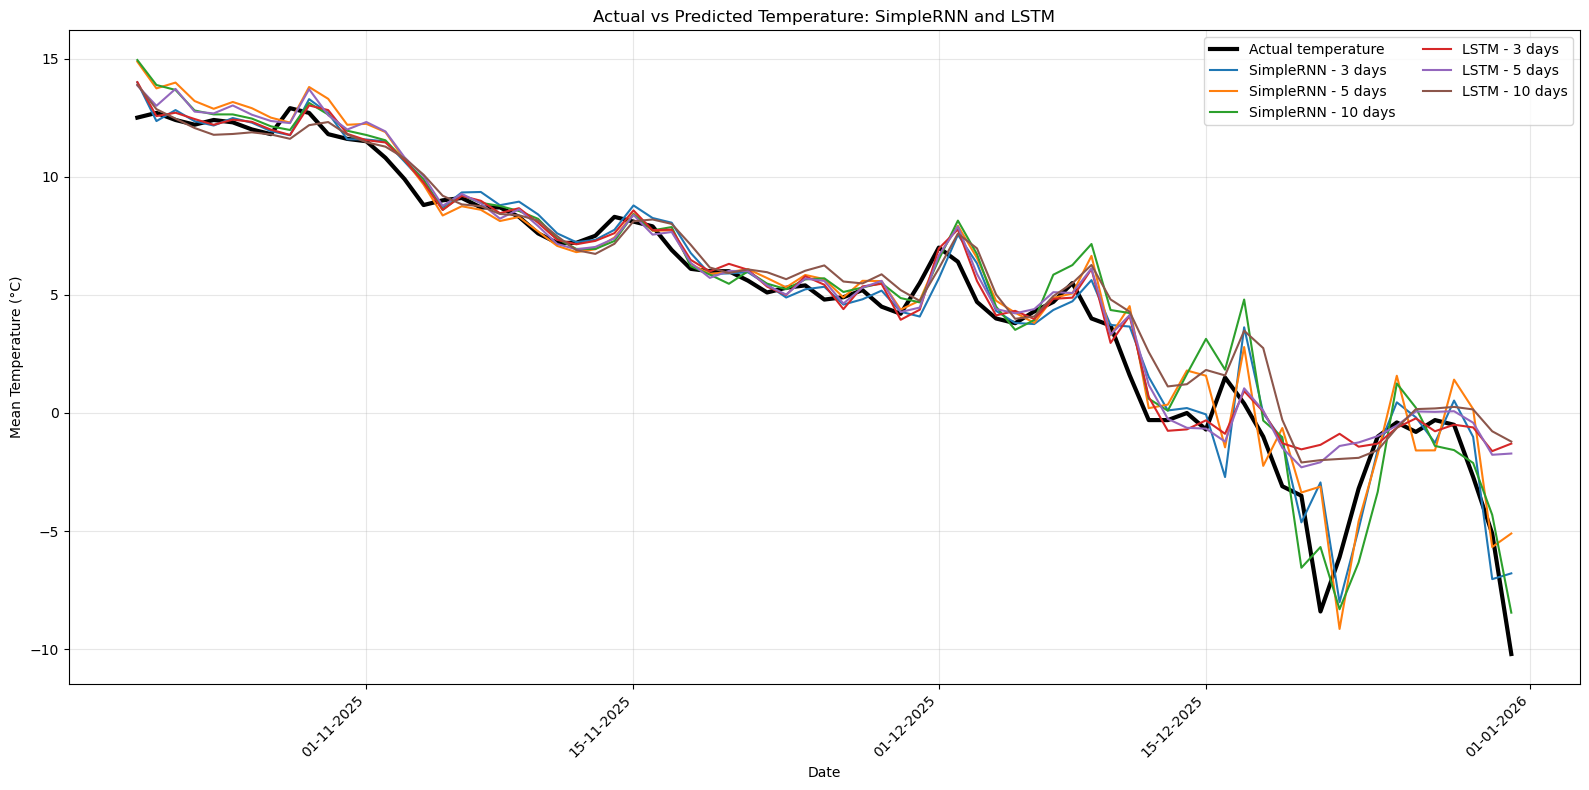

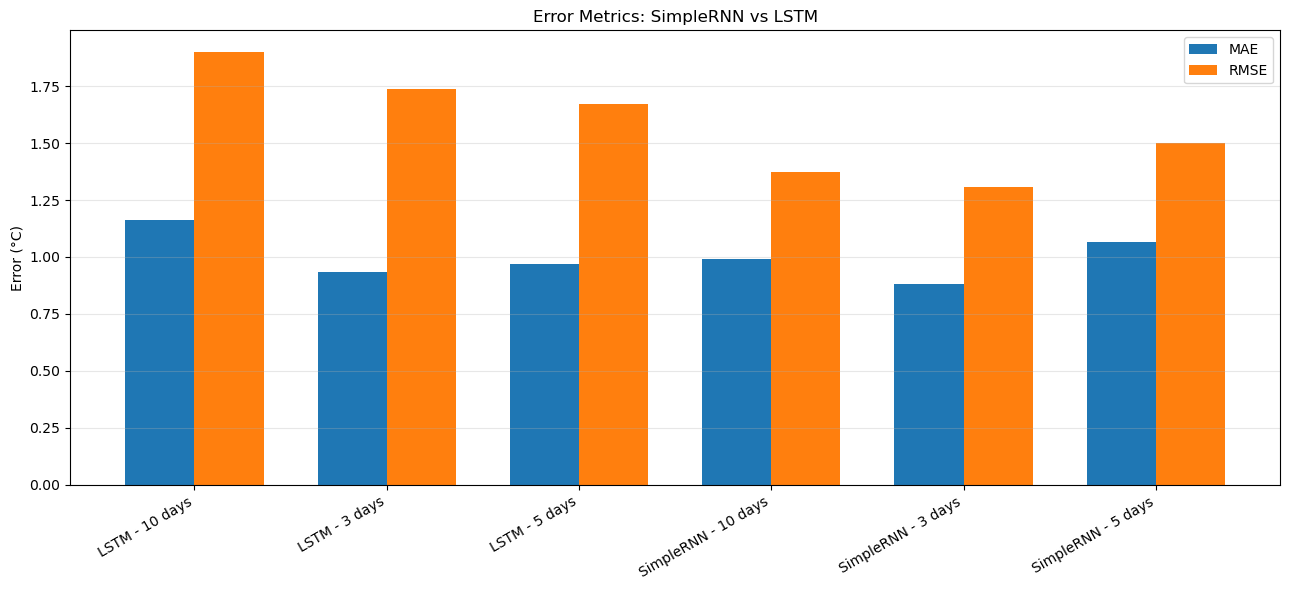

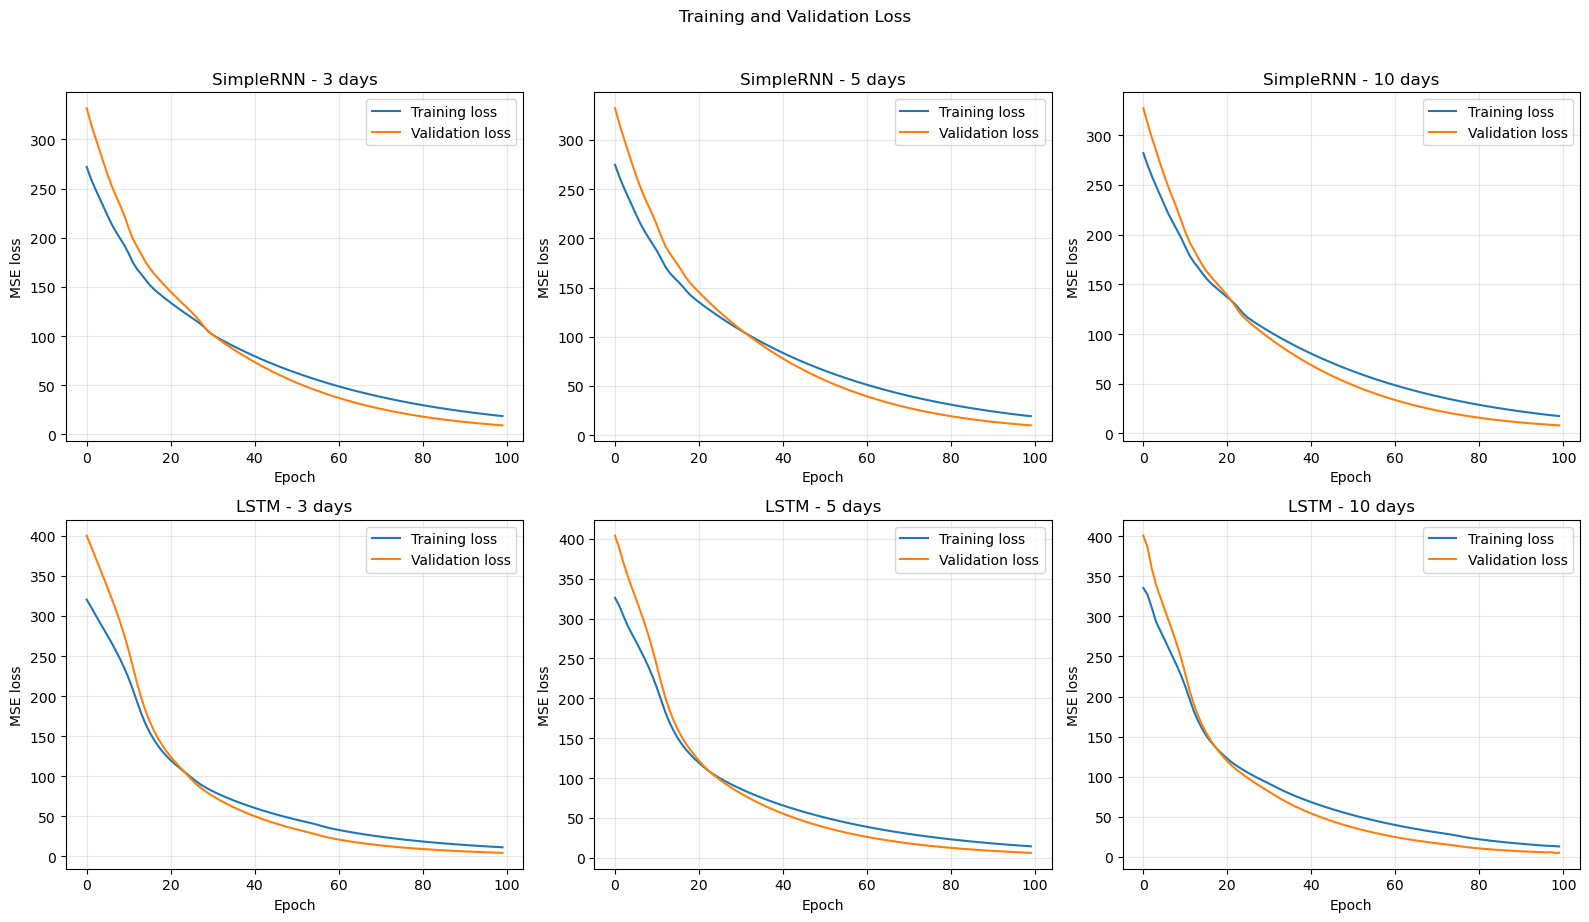

جدول‌ها و نمودارها در پوشه results ذخیره شدند.


In [22]:
# ذخیره جدول مقایسه مدل‌ها
comparison_df.to_csv(RESULTS_DIR / "SimpleRNN_vs_LSTM_comparison.csv", index=True)
comparison_df.to_excel(RESULTS_DIR / "SimpleRNN_vs_LSTM_comparison.xlsx", index=True)
comparison_all.to_csv(RESULTS_DIR / "all_models_predictions_common_dates.csv", index=False)

# نمودار نهایی: دمای واقعی در برابر پیش‌بینی هر شش مدل
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(
    comparison_all["date"], comparison_all["Actual"],
    label="Actual temperature", linewidth=3, color="black"
)

for model_name in all_results:
    prediction_column = model_name.replace(" ", "_").replace("-", "")
    ax.plot(
        comparison_all["date"], comparison_all[prediction_column],
        label=model_name, linewidth=1.5
    )

ax.set_title("Actual vs Predicted Temperature: SimpleRNN and LSTM")
ax.set_xlabel("Date")
ax.set_ylabel("Mean Temperature (°C)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m-%Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "all_six_models_prediction_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# نمودار مقایسه معیارهای خطا
metrics_plot = comparison_df.sort_values("Model")
fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(metrics_plot))
width = 0.36
ax.bar(x - width/2, metrics_plot["MAE (°C)"], width, label="MAE")
ax.bar(x + width/2, metrics_plot["RMSE (°C)"], width, label="RMSE")
ax.set_xticks(x)
ax.set_xticklabels(metrics_plot["Model"], rotation=30, ha="right")
ax.set_ylabel("Error (°C)")
ax.set_title("Error Metrics: SimpleRNN vs LSTM")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "all_six_models_error_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

# نمودار روند loss آموزش و اعتبارسنجی برای هر شش مدل
all_histories = {
    "SimpleRNN - 3 days": history_3,
    "SimpleRNN - 5 days": history_5,
    "SimpleRNN - 10 days": history_10,
    "LSTM - 3 days": history_lstm_3,
    "LSTM - 5 days": history_lstm_5,
    "LSTM - 10 days": history_lstm_10
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (model_name, history) in zip(axes.flat, all_histories.items()):
    ax.plot(history.history["loss"], label="Training loss")
    if "val_loss" in history.history:
        ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle("Training and Validation Loss", y=1.02)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_validation_loss_all_models.png", dpi=300, bbox_inches="tight")
plt.show()

print("جدول‌ها و نمودارها در پوشه results ذخیره شدند.")

## خروجی‌های ذخیره‌شده

پس از اجرای نوت‌بوک از ابتدا تا انتها، پوشه `results/` شامل موارد زیر خواهد بود:

- نمودار پیش‌بینی جداگانه برای هر یک از شش مدل
- نمودار مقایسه دمای واقعی با پیش‌بینی هر شش مدل روی تاریخ‌های مشترک
- نمودار مقایسه MAE و RMSE
- نمودار `loss` آموزش و اعتبارسنجی برای شش مدل
- جدول معیارهای مقایسه و پیش‌بینی‌های هم‌تراز

**نکته:** این فایل نوت‌بوک کدهای رسم و ذخیره نمودارها را اضافه می‌کند؛ برای تولید فایل‌های تصویری باید نوت‌بوک را اجرا کنی. فایل CSV داده‌ها باید در همان پوشه نوت‌بوک باشد، مگر اینکه مسیر آن را در کد تغییر بدهی.